# 02 Price EDA

Distribution, intraday/weekly shape, spikes and negatives, drift over time (see D-002).

## Init

In [1]:
import sys
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import pandas as pd
import matplotlib.pyplot as plt

from _common import load, load_all, to_uk, settlement_day, UK_TZ, dev_only

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.figsize": (11, 3.5), "lines.linewidth": 1.2})
BLUE, GREY = "#2a6fb0", "#8a8f98"

px = dev_only(load("imbalance_price")).set_index("period_start")["price_gbp_per_mwh"]  # development set only
uk = px.index.tz_convert(UK_TZ)
df = pd.DataFrame({"price": px.values, "date": uk.date, "month": uk.tz_localize(None).to_period("M"),
                   "hour": uk.hour + uk.minute / 60, "dow": uk.day_of_week}, index=px.index)
df["date"] = pd.to_datetime(df["date"])

def show():
    """Rotate x tick labels 45 degrees on every axis, then display."""
    for a in plt.gcf().axes:
        a.tick_params(axis="x", labelrotation=45)
    plt.tight_layout()
    plt.show()

## 1. The series over time
Daily median with the daily min-max range (clipped), to see level shifts and spike days.

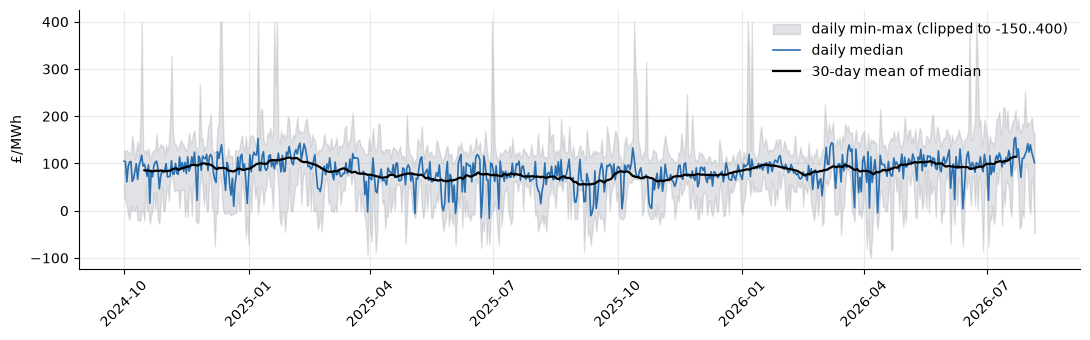

In [3]:
d = df.groupby("date")["price"].agg(["median", "min", "max"])
fig, ax = plt.subplots()
ax.fill_between(d.index, d["min"].clip(-150), d["max"].clip(upper=400), color=GREY, alpha=0.25, label="daily min-max (clipped to -150..400)")
ax.plot(d.index, d["median"], color=BLUE, label="daily median")
ax.plot(d.index, d["median"].rolling(30, center=True).mean(), color="black", lw=1.6, label="30-day mean of median")
ax.set_ylabel("£/MWh"); ax.legend(frameon=False, loc="upper right"); show()

## 2. Distribution
Quantiles overall and by quarter; fat tails and negatives.

0.001    -73.9
0.010    -26.0
0.050     -1.6
0.250     64.1
0.500     88.4
0.750    114.0
0.950    147.0
0.990    179.0
0.999    444.7
         0.05    0.5   0.95  neg_share  spike_share    std
quarter                                                   
2024Q4    0.0   87.5  140.0      0.039       0.0036   48.1
2025Q1   12.3   96.7  156.7      0.033       0.0044  135.1
2025Q2  -15.9   72.7  128.0      0.107       0.0009   46.2
2025Q3  -11.4   69.4  123.4      0.082       0.0000   40.2
2025Q4    4.8   74.7  123.0      0.034       0.0007   35.9
2026Q1   18.0   90.8  150.0      0.024       0.0025   41.6
2026Q2   -5.7   96.9  152.8      0.057       0.0025   51.9
2026Q3   -6.5  114.3  174.5      0.069       0.0000   49.4


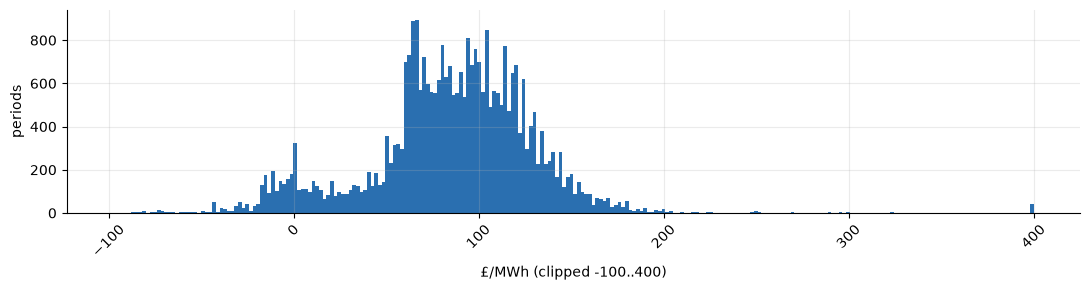

In [4]:
q = [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]
print(df["price"].quantile(q).round(1).to_string())
df["quarter"] = df["month"].dt.asfreq("Q")
print(df.groupby("quarter")["price"].quantile([.05, .5, .95]).unstack().round(1).assign(
    neg_share=df.groupby("quarter")["price"].apply(lambda s: (s < 0).mean()).round(3),
    spike_share=df.groupby("quarter")["price"].apply(lambda s: (s > 300).mean()).round(4),
    std=df.groupby("quarter")["price"].std().round(1)))
fig, ax = plt.subplots(figsize=(11, 3)); ax.hist(df["price"].clip(-100, 400), bins=250, color=BLUE)
ax.set_xlabel("£/MWh (clipped -100..400)"); ax.set_ylabel("periods"); show()

## 3. Intraday and weekly shape
Median and 10-90% band by half-hour of the UK day; median by weekday.

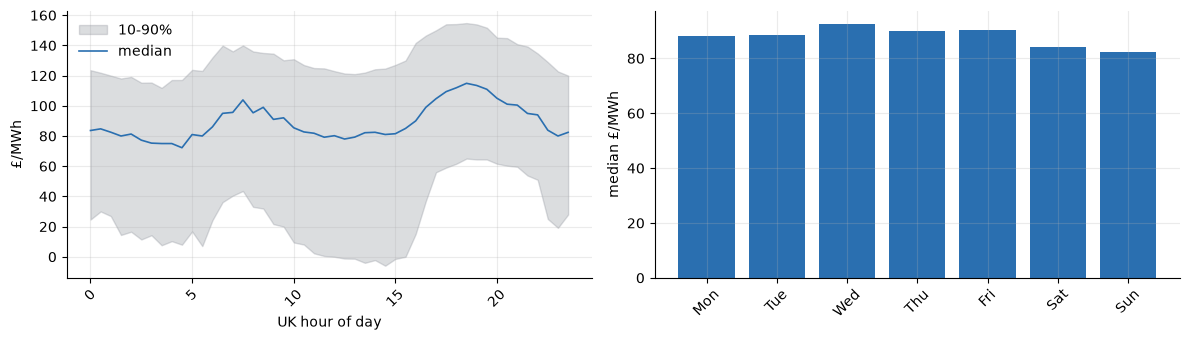

hour
0.0      84.0
2.0      81.0
4.0      75.0
6.0      86.0
8.0      95.0
10.0     85.0
12.0     80.0
14.0     82.0
16.0     90.0
18.0    112.0
20.0    105.0
22.0     94.0


In [5]:
g = df.groupby("hour")["price"]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].fill_between(g.median().index, g.quantile(.1), g.quantile(.9), color=GREY, alpha=0.3, label="10-90%")
axs[0].plot(g.median(), color=BLUE, label="median"); axs[0].set_xlabel("UK hour of day"); axs[0].set_ylabel("£/MWh"); axs[0].legend(frameon=False)
w = df.groupby("dow")["price"].median(); axs[1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], w.values, color=BLUE); axs[1].set_ylabel("median £/MWh")
show()
print(g.median().round(0).iloc[::4].to_string())

## 4. Drift (D-002)
Monthly level, spread and daily range. If battery growth changed the market, daily spreads or the volatility profile should shift.

In [6]:
dd = df.groupby("date")["price"].agg(lambda s: s.quantile(.9) - s.quantile(.1)).rename("spread_p90_p10").to_frame()
dd["month"] = dd.index.to_period("M")
m = df.groupby("month")["price"].agg(median="median", std="std", neg_share=lambda s: (s < 0).mean(),
                                      p05=lambda s: s.quantile(.05), p95=lambda s: s.quantile(.95)).round(2)
m["daily_spread_p90_p10"] = dd.groupby("month")["spread_p90_p10"].median().round(1)
m["mean"] = df.groupby("month")["price"].mean().round(1)
m

,median,std,neg_share,p05,p95,daily_spread_p90_p10,mean
month,,,,,,,
2024-10,87.10,49.03,0.03,0.00,129.00,76.1,81.6
2024-11,87.98,35.08,0.02,32.11,139.00,62.1,93.7
2024-12,88.00,56.48,0.06,-4.00,155.78,102.0,86.2
2025-01,104.99,222.16,0.03,24.08,165.00,88.5,123.9
2025-02,99.06,41.14,0.02,15.03,159.13,61.7,100.7
2025-03,81.32,37.98,0.04,8.53,140.00,71.2,87.8
2025-04,73.22,41.22,0.07,-11.98,129.50,76.5,74.9
2025-05,67.96,40.52,0.09,-11.33,122.96,78.3,69.4
2025-06,80.68,55.28,0.16,-17.22,129.05,110.4,69.1


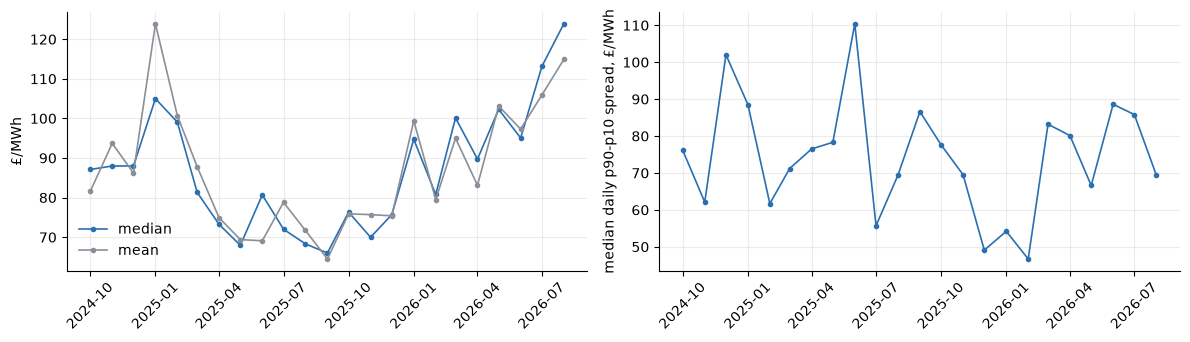

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
x = m.index.to_timestamp()
axs[0].plot(x, m["median"], color=BLUE, marker="o", ms=3, label="median"); axs[0].plot(x, m["mean"], color=GREY, marker="o", ms=3, label="mean"); axs[0].set_ylabel("£/MWh"); axs[0].legend(frameon=False)
axs[1].plot(x, m["daily_spread_p90_p10"], color=BLUE, marker="o", ms=3); axs[1].set_ylabel("median daily p90-p10 spread, £/MWh")
show()

## 5. How predictable is it from its own past?
Correlation with the same period 1 day / 7 days earlier, and by horizon. For a day-ahead forecast the usable own-price history ends at D-1 ~07:00, so lags of at least 24h + the time to the period are what exist.

In [8]:
s = px.asfreq("30min")
for lag, name in [(48, "1 day"), (96, "2 days"), (336, "7 days")]:
    print(f"corr with {name} earlier: {s.corr(s.shift(lag)):.3f}   MAE of naive: {(s - s.shift(lag)).abs().mean():.1f}   RMSE: {((s - s.shift(lag))**2).mean()**.5:.1f}")
dm = s.groupby(s.index.tz_convert(UK_TZ).date).mean()
print("daily-mean autocorr lag1:", round(dm.autocorr(1), 3), " lag7:", round(dm.autocorr(7), 3))

corr with 1 day earlier: 0.159   MAE of naive: 39.1   RMSE: 85.2
corr with 2 days earlier: 0.129   MAE of naive: 41.7   RMSE: 86.8
corr with 7 days earlier: 0.117   MAE of naive: 42.7   RMSE: 87.5
daily-mean autocorr lag1: 0.319  lag7: 0.127


## 6. Spikes and negatives
When do they happen, and how clustered are they?

In [9]:
hi, lo = df["price"] > 300, df["price"] < 0
print("spikes >300:", hi.sum(), "| negatives:", lo.sum())
print(pd.DataFrame({"spike_share_by_hour": hi.groupby(df["hour"]).mean(), "neg_share_by_hour": lo.groupby(df["hour"]).mean()}).iloc[::4].round(3).T.to_string())
print(); print("spike days (periods >300):"); print(df[hi].groupby("date").size().sort_values(ascending=False).head(8).to_string())
print(); print("monthly negative share:"); print(m["neg_share"].round(3).to_string())

spikes >300: 64 | negatives: 1767
hour                 0.0    2.0    4.0   6.0    8.0    10.0   12.0  14.0   16.0   18.0   20.0   22.0
spike_share_by_hour  0.00  0.000  0.000  0.00  0.000  0.003  0.003  0.00  0.003  0.007  0.001  0.001
neg_share_by_hour    0.03  0.042  0.077  0.05  0.056  0.080  0.099  0.11  0.061  0.009  0.007  0.018

spike days (periods >300):
date
2025-01-08    13
2026-06-23     9
2024-12-12     7
2024-10-14     5
2026-01-05     5
2025-01-20     4
2025-06-30     4
2024-12-11     3

monthly negative share:
month
2024-10    0.03
2024-11    0.02
2024-12    0.06
2025-01    0.03
2025-02    0.02
2025-03    0.04
2025-04    0.07
2025-05    0.09
2025-06    0.16
2025-07    0.03
2025-08    0.08
2025-09    0.13
2025-10    0.07
2025-11    0.03
2025-12    0.01
2026-01    0.00
2026-02    0.01
2026-03    0.06
2026-04    0.09
2026-05    0.02
2026-06    0.07
2026-07    0.07
2026-08    0.04
Freq: M


## Findings (development set: UK days before 2026-08-06)

- **Distribution:** median £88, 5-95% range about -2 to 147, very fat right tail (99.9% at £445, max £2,900 on 2025-01-08). 1,767 periods (5.5%) are negative; 64 exceed £300. Spikes are rare and cluster on a few days (2025-01-08 alone has 13 periods over £300). MAE and RMSE will differ a lot because of this.
- **Intraday shape:** evening peak (median about £112 at 18:00), lowest about £75 at 04:00, with a smaller morning bump around 08:00. Negatives concentrate in the daytime (8-11% of periods 10:00-15:00, under 1% around 18:00-20:00). Spikes mostly at 18:00. Weekday effect is small (weekends a few pounds lower). Time of day carries real signal.
- **Level is not stable (D-002):** monthly median was about £66-76 in mid/late 2025, rose to £90-102 in spring 2026 and £113 in July 2026 (£124 for the 5 days of August in the development set). Daily p90-p10 spread has no clear trend (monthly median 47-110). So the main drift is in level, not obviously in spread. Needs a recent-level feature and bias reporting.
- **Negatives are seasonal:** high in spring/summer 2025 (Jun 2025 16%, Sep 2025 13%), near zero in winter.
- **Own-price persistence is weak:** correlation with the same period 1 day earlier is 0.16 (2 days 0.13, 7 days 0.12); daily-mean autocorrelation lag 1 is 0.32. Naive lag MAE: 39.1 (1 day), 41.7 (2 days), 42.7 (7 days); RMSE 85-88.
- **Caveat for baselines:** "same period yesterday" (D-1) is not available at the cutoff for most of day D, since D-1 prices after about 07:00 are unknown. The honest naive baseline is D-2 (lag 96) or the last known price level, not lag 48. Handle this in 04.

**Implications**
- Features: hour of day, day of week, season, plus a recent-level feature built only from prices known at the cutoff (e.g. mean of the last 7 days up to D-1 07:00).
- Validation: chronological rolling folds inside the development set; report bias as well as MAE/RMSE.
- Robust loss or clipping for training to cope with spikes; evaluate with both MAE and RMSE.
